# Pondweed habitat conditions at Longtail Point

Evaluate every scenario in `michiganhuron_avg.csv` at the fixed lake-floor elevation set by `BOTTOM_FT` (574-576 ft; saved outputs: **575 ft**). The floor and lake levels share the same vertical datum (confirmed by the user). Water years begin **January 1**, so water-year and calendar-year labels coincide.

| Component | Monthly conditions | Qualifying water year |
| --- | --- | --- |
| Winter survival | Depth >=0.5 m, January through December | All 12 months meet the depth condition |
| Growing season | May through August inclusive; depth 1-3 m inclusive; signed monthly rise <=0.15 m | All four seasonal months meet both depth and rise conditions |

**Interview decisions:** falls are unrestricted. Differences are computed **within each year's May-August season**, giving June-minus-May, July-minus-June, and August-minus-July. May is not compared with April; its rate is NaN and **passes the rate characteristic**. Any other NaN rate also passes, as requested, but this does not turn an unavailable depth into success.

**Surface metric:** `100 x qualifying complete years / all complete years`. This is neither the percentage of qualifying months nor an event rate. These are two separate habitat components; no joint survival-and-growth criterion is added.

Monthly average lake levels are used directly, without moving-average smoothing or daily interpolation. Passing every monthly average does **not** establish that a threshold held every day. These configured habitat conditions are not a validated model of pondweed survival, growth, or recruitment; temperature, light, ice, waves, sediment, and species-specific tolerances are outside the analysis.

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from climate_canvas.plots_utilities import plot_response_surface
from IPython.display import Markdown, display
from matplotlib.colors import Normalize, TwoSlopeNorm

from hydropattern.parsers import magnitude_parser, timing_parser
from hydropattern.patterns import Characteristic, CharacteristicType, Component
from hydropattern.scenario_grid import build_grid, parse_scenario_name
from hydropattern.scenarios import evaluate_scenarios
from hydropattern.timeseries import Timeseries


## Units, timing, and the custom rise characteristic

Use the exact international-foot conversion, **1 ft = 0.3048 m**. Integer-foot floors have exactly four decimal places in meters; retain that precision to avoid a floating-point conversion artifact rejecting an equal boundary level. Input lake levels are not rounded:

- Floor elevation = `BOTTOM_FT x 0.3048` (575 ft: 175.2600 m in the saved outputs).
- Water depth = lake elevation minus `175.2600 m`; negative values mean the fixed floor is above the lake level and are not clipped.
- Winter minimum lake elevation = **175.7600 m**.
- Growing-season lake elevation interval = **176.2600-178.2600 m**, inclusive.

Hydropattern timing uses a leap-normalized 365-day calendar: May 1 is day **121**, August 31 is day **243**. Monthly timestamps are on the first, so the selected observations are days **121, 152, 182, 213**, in both leap and non-leap years.

The built-in `rate_of_change_parser` evaluates a level **ratio**. It cannot represent a limit in m/month. A notebook-local `Characteristic` instead compares **signed differences** of adjacent seasonal monthly averages. Constant floor elevation cancels from differences, so changes in lake elevation and water depth are identical. This is per calendar-month timestep, not m/day or a fixed 30-day interval. A `1e-12 m` absolute tolerance resolves floating-point representation at the inclusive 0.15 m boundary; it is not an ecological tolerance.

In [2]:
BOTTOM_FT = 575.0  # ft IGLD85; run 574..576
BOTTOM_M = round(BOTTOM_FT * 0.3048, 4)
WINTER_LEVEL_M = BOTTOM_M + 0.5
GROWING_LEVELS_M = (BOTTOM_M + 1.0, BOTTOM_M + 3.0)
GROWING_MONTHS = (5, 6, 7, 8)
GROWING_DOY = (121, 243)
MAX_RISE_M = 0.15


def seasonal_rises(levels: pd.Series) -> pd.Series:
    seasonal_levels = levels.where(levels.index.month.isin(GROWING_MONTHS))
    return seasonal_levels.groupby(levels.index.year).diff()


def rise_outcomes(frame: pd.DataFrame) -> pd.Series:
    rises = seasonal_rises(frame.iloc[:, 0])
    passes = rises.isna() | rises.le(MAX_RISE_M) | np.isclose(
        rises, MAX_RISE_M, rtol=0, atol=1e-12)
    return passes.astype(float)


def monthly_rise_fx(frame: pd.DataFrame, output=None) -> np.ndarray:
    return rise_outcomes(frame).to_numpy(dtype=float)


winter = Component(
    name='winter_survival',
    characteristics=[magnitude_parser(['>=', WINTER_LEVEL_M], order=1)
                     ._replace(name='minimum_depth')],
    is_success_pattern=True,
)
growing = Component(
    name='growing_season_habitat',
    characteristics=[
        timing_parser(list(GROWING_DOY), order=1)._replace(name='growing_season'),
        magnitude_parser(list(GROWING_LEVELS_M), order=2)._replace(name='magnitude'),
        Characteristic(name='monthly_rise', fx=monthly_rise_fx,
                       type=CharacteristicType.RATE_OF_CHANGE),
    ],
    is_success_pattern=True,
)


## Annual reporting contract

The components produce monthly diagnostic and final outcomes through hydropattern's standard scenario evaluator. The annual reducer below assesses those final outcomes over exactly the required months, **only within complete January-December years**. In particular, September-April timing failures are not growing-season failures, and the package's default all-timestep `portion` summary is not used.

At the annual level, one definite failed required month settles failure; all required months passing settles success; otherwise the year is unknown. Unknown years remain in the complete-year denominator. Their percentage bounds are disclosed and their scalar surface value is withheld, not assigned zero or a midpoint. Partial endpoint years are excluded and reported. Missing or duplicate monthly timestamps are rejected. The current hydropattern evaluator rejects missing input levels; the loading cell explicitly reports and rejects non-finite levels rather than disguising them as rate-only NaNs. NaN rate success is a deliberate, separate override of ordinary unknown-outcome handling.

In [3]:
def complete_year_labels(dates: pd.DatetimeIndex) -> list[int]:
    if dates.hasnans or not dates.is_unique or not dates.is_monotonic_increasing:
        raise ValueError('Monthly timestamps must be valid, unique, and increasing.')
    if len(dates) < 2 or not (dates.day == 1).all() or not np.all(
            np.diff(dates.year * 12 + dates.month) == 1):
        raise ValueError('Expected consecutive monthly observations on the first of each month.')
    counts = pd.Series(dates.year).value_counts().sort_index()
    return counts.index[counts.eq(12)].tolist()


def annual_verdicts(outcomes: pd.Series, required_months: tuple[int, ...]) -> pd.Series:
    complete = complete_year_labels(outcomes.index)
    if not complete:
        raise ValueError('No complete January-December water years are available.')
    verdicts = {}
    for label, year in outcomes.groupby(outcomes.index.year):
        if label not in complete:
            continue
        required = year.loc[year.index.month.isin(required_months)]
        if len(required) != len(required_months):
            raise ValueError('Required monthly observations are not unique and complete.')
        verdicts[int(label)] = (
            0.0 if required.eq(0).any() else 1.0 if required.eq(1).all() else np.nan)
    return pd.Series(verdicts, name=outcomes.name, dtype=float).rename_axis('Water year')


def annual_summary(annual: pd.Series) -> dict[str, float | int]:
    total = len(annual)
    if total == 0:
        raise ValueError('Annual percentages require at least one complete water year.')
    qualifying = int(annual.eq(1).sum())
    unknown = int(annual.isna().sum())
    lower = 100 * qualifying / total
    upper = 100 * (qualifying + unknown) / total
    return {
        'Complete years': total, 'Qualifying years': qualifying,
        'Failed years': int(annual.eq(0).sum()), 'Unknown years': unknown,
        'Percentage': lower if unknown == 0 else np.nan,
        'Lower percentage': lower, 'Upper percentage': upper,
    }


In [4]:
example = next(
    root / 'data' / 'avg'
    for root in (Path.cwd(), *Path.cwd().parents)
    if (root / 'data' / 'avg' / 'michiganhuron_avg.csv').is_file()
)
ts = Timeseries.from_csv(str(example / 'michiganhuron_avg.csv'),
                         first_dowy=1, date_format='%Y-%m-%d')
scenario_names = list(ts.data.columns[:-1])
dates = ts.data.index
complete_years = set(complete_year_labels(dates))
levels = ts.data[scenario_names]
nonfinite = pd.Series((~np.isfinite(levels.to_numpy(dtype=float))).sum(axis=0),
                     index=scenario_names, name='Non-finite levels')
if nonfinite.gt(0).any():
    display(nonfinite[nonfinite.gt(0)])
    raise ValueError('Missing/infinite input levels cannot be evaluated by hydropattern; '
                     'NaN-as-success applies only to the rise characteristic.')
if not complete_years:
    raise ValueError('No complete January-December water years.')
excluded_years = sorted(set(dates.year) - complete_years)
if '_0_0' not in scenario_names or any(parse_scenario_name(name) is None for name in scenario_names):
    raise ValueError('Expected baseline _0_0 and precipitation/temperature scenario names.')
print(f'{len(dates):,} consecutive monthly averages; {len(complete_years):,} complete years; '
      f'{len(scenario_names)} scenarios; no missing levels.')
print(f'Record: {dates[0]:%Y-%m} through {dates[-1]:%Y-%m}; excluded partial years: {excluded_years}')
print(f'Floor: {BOTTOM_M:.4f} m; winter minimum: {WINTER_LEVEL_M:.4f} m; '
      f'growing interval: {GROWING_LEVELS_M[0]:.4f}-{GROWING_LEVELS_M[1]:.4f} m.')
display(levels.head())


12,360 consecutive monthly averages; 1,030 complete years; 17 scenarios; no missing levels.
Record: 1970-01 through 2999-12; excluded partial years: []
Floor: 175.2600 m; winter minimum: 175.7600 m; growing interval: 176.2600-178.2600 m.


,_0_0,_0_1.5,_0_3,_0_5,_0_7,_5_1.5,_5_3,_5_5,_5_7,_10_3,_10_5,_10_7,_15_3,_15_5,_15_7,_20_5,_20_7
time,,,,,,,,,,,,,,,,,
1970-01-01,176.63,176.19,175.78,175.22,174.60,176.70,176.30,175.78,175.18,176.73,176.23,175.66,177.25,176.76,176.21,177.33,176.81
1970-02-01,176.63,176.19,175.78,175.24,174.61,176.71,176.32,175.80,175.21,176.75,176.25,175.68,177.26,176.78,176.24,177.36,176.85
1970-03-01,176.67,176.25,175.83,175.29,174.67,176.76,176.37,175.86,175.27,176.81,176.32,175.75,177.33,176.85,176.31,177.44,176.93
1970-04-01,176.76,176.34,175.92,175.38,174.76,176.87,176.46,175.95,175.37,176.92,176.42,175.86,177.44,176.96,176.42,177.57,177.07
1970-05-01,176.82,176.38,175.95,175.41,174.81,176.91,176.50,175.99,175.41,176.96,176.47,175.91,177.48,177.00,176.47,177.63,177.13


In [5]:
evaluated = evaluate_scenarios(ts, [winter, growing])
component_results = {component.name: evaluated.by_component(component.name)
                     for component in (winter, growing)}
required_months = {winter.name: tuple(range(1, 13)), growing.name: GROWING_MONTHS}
annual_outcomes = {}
summary_rows = []
for component in (winter, growing):
    annual_outcomes[component.name] = pd.DataFrame({
        name: annual_verdicts(result.df[component.name], required_months[component.name])
        for name, result in component_results[component.name].items()
    })
    for name in scenario_names:
        precipitation, temperature = parse_scenario_name(name)
        summary_rows.append({
            'Component': component.name, 'Scenario': name,
            'Precipitation delta (%)': precipitation, 'Temperature delta (deg C)': temperature,
            **annual_summary(annual_outcomes[component.name][name]),
        })
summary = pd.DataFrame(summary_rows).set_index(['Component', 'Scenario'])
with pd.option_context('display.max_rows', None, 'display.max_columns', None):
    display(summary.round(3))
baseline_summary = summary.xs('_0_0', level='Scenario')
display(baseline_summary[['Complete years', 'Qualifying years', 'Failed years',
                          'Unknown years', 'Percentage']].round(3))


Precipitation delta (%)  \
Component              Scenario                            
winter_survival        _0_0                          0.0   
                       _0_1.5                        0.0   
                       _0_3                          0.0   
                       _0_5                          0.0   
                       _0_7                          0.0   
                       _5_1.5                        5.0   
                       _5_3                          5.0   
                       _5_5                          5.0   
                       _5_7                          5.0   
                       _10_3                        10.0   
                       _10_5                        10.0   
                       _10_7                        10.0   
                       _15_3                        15.0   
                       _15_5                        15.0   
                       _15_7                        15.0   
                       _20_5                        20.0   
                       _20_7                        20.0   
growing_season_habitat _0_0                          0.0   
                       _0_1.5                        0.0   
                       _0_3                          0.0   
                       _0_5                          0.0   
                       _0_7                          0.0   
                       _5_1.5                        5.0   
                       _5_3                          5.0   
                       _5_5                          5.0   
                       _5_7                          5.0   
                       _10_3                        10.0   
                       _10_5                        10.0   
                       _10_7                        10.0   
                       _15_3                        15.0   
                       _15_5                        15.0   
                       _15_7                        15.0   
                       _20_5                        20.0   
                       _20_7                        20.0   

                                 Temperature delta (deg C)  Complete years  \
Component              Scenario                                              
winter_survival        _0_0                            0.0            1030   
                       _0_1.5                          1.5            1030   
                       _0_3                            3.0            1030   
                       _0_5                            5.0            1030   
                       _0_7                            7.0            1030   
                       _5_1.5                          1.5            1030   
                       _5_3                            3.0            1030   
                       _5_5                            5.0            1030   
                       _5_7                            7.0            1030   
                       _10_3                           3.0            1030   
                       _10_5                           5.0            1030   
                       _10_7                           7.0            1030   
                       _15_3                           3.0            1030   
                       _15_5                           5.0            1030   
                       _15_7                           7.0            1030   
                       _20_5                           5.0            1030   
                       _20_7                           7.0            1030   
growing_season_habitat _0_0                            0.0            1030   
                       _0_1.5                          1.5            1030   
                       _0_3                            3.0            1030   
                       _0_5                            5.0            1030   
                       _0_7                            7.0            1030   


,Complete years,Qualifying years,Failed years,Unknown years,Percentage
Component,,,,,
winter_survival,1030,1008,22,0,97.864
growing_season_habitat,1030,814,216,0,79.029


## Baseline diagnostics: what limits habitat?

The table separates all-season depth qualification from all-season rise qualification and their conjunction. Depth failures are also split into below 1 m and above 3 m; these failure categories can overlap within a year and must not be added as independent counts. The rise condition permits all drawdowns; it does not imply stable water levels.

The short example below shows the first baseline growing season, including May's intentional rate pass. The depth-duration curve summarizes all recorded monthly averages, while the annual diagnostics summarize complete years. Neither replaces the component's all-required-months annual test.

,Qualifying years,Failed years,Percentage
All 12 months: depth >=0.5 m,1008.0,22.0,97.864
All May-Aug months: depth 1-3 m,827.0,203.0,80.291
All May-Aug months: rise <=0.15 m (May passes),1015.0,15.0,98.544
All May-Aug months: depth >=1 m,827.0,203.0,80.291
All May-Aug months: depth <=3 m,1030.0,0.0,100.000
All May-Aug months: combined growing habitat,814.0,216.0,79.029


Baseline seasonal NaN-rate passes: 1,030; May observations: 1,030; other seasonal NaN rates: 0.


,Lake elevation (m),Depth (m),Seasonal rise (m/month),Depth outcome,Rise outcome,Growing component outcome
time,,,,,,
1970-05-01,176.82,1.56,NaN,1.0,1.0,1.0
1970-06-01,176.82,1.56,0.00,1.0,1.0,1.0
1970-07-01,176.81,1.55,-0.01,1.0,1.0,1.0
1970-08-01,176.79,1.53,-0.02,1.0,1.0,1.0


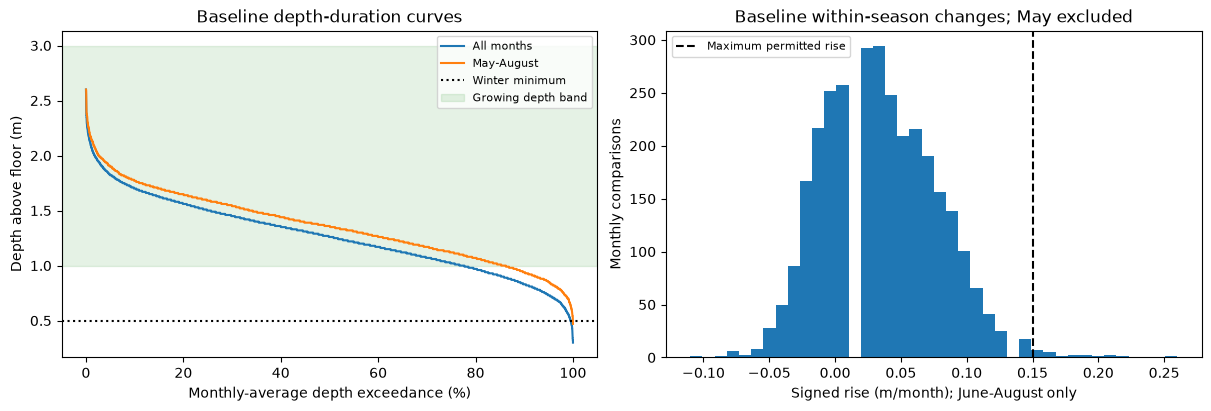

In [6]:
baseline = levels['_0_0']
baseline_depth = baseline - BOTTOM_M
baseline_rises = seasonal_rises(baseline)
baseline_growing = component_results[growing.name]['_0_0'].df
diagnostic_conditions = {
    'All 12 months: depth >=0.5 m': (baseline_depth.ge(0.5), tuple(range(1, 13))),
    'All May-Aug months: depth 1-3 m': (baseline_growing['magnitude'], GROWING_MONTHS),
    'All May-Aug months: rise <=0.15 m (May passes)': (baseline_growing['monthly_rise'], GROWING_MONTHS),
    'All May-Aug months: depth >=1 m': (baseline_depth.ge(1.0), GROWING_MONTHS),
    'All May-Aug months: depth <=3 m': (baseline_depth.le(3.0), GROWING_MONTHS),
    'All May-Aug months: combined growing habitat': (baseline_growing[growing.name], GROWING_MONTHS),
}
diagnostics = pd.DataFrame({
    label: annual_summary(annual_verdicts(condition.astype(float), months))
    for label, (condition, months) in diagnostic_conditions.items()
}).T
display(diagnostics[['Qualifying years', 'Failed years', 'Percentage']].round(3))
season_mask = dates.month.isin(GROWING_MONTHS)
may_mask = dates.month == 5
print(f'Baseline seasonal NaN-rate passes: {baseline_rises[season_mask].isna().sum():,}; '
      f'May observations: {may_mask.sum():,}; '
      f'other seasonal NaN rates: {baseline_rises[season_mask & ~may_mask].isna().sum():,}.')
first_year = min(complete_years)
detail = pd.DataFrame({
    'Lake elevation (m)': baseline, 'Depth (m)': baseline_depth,
    'Seasonal rise (m/month)': baseline_rises,
    'Depth outcome': baseline_growing['magnitude'],
    'Rise outcome': baseline_growing['monthly_rise'],
    'Growing component outcome': baseline_growing[growing.name],
})
display(detail.loc[(dates.year == first_year) & season_mask].round(4))

fig, axes = plt.subplots(1, 2, figsize=(12, 4), constrained_layout=True)
for depth, label in [(baseline_depth, 'All months'),
                     (baseline_depth[season_mask], 'May-August')]:
    ordered = np.sort(depth.to_numpy())[::-1]
    exceedance = 100 * np.arange(1, len(ordered) + 1) / len(ordered)
    axes[0].plot(exceedance, ordered, label=label)
axes[0].axhline(0.5, color='black', linestyle=':', label='Winter minimum')
axes[0].axhspan(1, 3, color='green', alpha=0.1, label='Growing depth band')
axes[0].set(xlabel='Monthly-average depth exceedance (%)', ylabel='Depth above floor (m)',
            title='Baseline depth-duration curves')
axes[0].legend(fontsize=8)
axes[1].hist(baseline_rises[season_mask].dropna(), bins=40)
axes[1].axvline(MAX_RISE_M, color='black', linestyle='--', label='Maximum permitted rise')
axes[1].set(xlabel='Signed rise (m/month); June-August only', ylabel='Monthly comparisons',
            title='Baseline within-season changes; May excluded')
axes[1].legend(fontsize=8)
plt.show()
plt.close(fig)


## Scenario response surfaces

Precipitation delta is horizontal; temperature delta is vertical. Each component's **unrounded `_0_0` baseline percentage is the color-bar midpoint (white)** for both the raw and interpolated/filled variants. A `TwoSlopeNorm` keeps endpoints at 0% and 100%, mapping the baseline to 0.5. This gives different percentage-per-color slopes below and above the baseline; compare numeric percentages rather than colors across components or sites. Color-bar ticks and contours are evenly spaced in normalized color coordinates, explicitly including the baseline. Its contour is emphasized. If a baseline is exactly 0% or 100%, a symmetric extended display range keeps it centered; values outside 0-100% on that scale are display padding, not feasible percentages. Unknown baselines raise an error rather than inventing a center.

The raw plot preserves absent scenario combinations as blank cells; supplied-cell values are percentages of qualifying complete years. The second plot explicitly requests `interpolate=True, fillin=True`: values between supplied cells are **spatial estimates**, not additional evaluated scenarios. Consult the exact scenario table when interpreting these estimates.

Unknown annual verdicts, if present, are withheld from the raw grid and block the filled variant so spatial filling cannot conceal outcome uncertainty. No coverage subtitle, midpoint substitution for uncertain outcomes, or event-count statistic is used.

### Winter survival: depth >=0.5 m in all 12 months

Precipitation delta (%),0.0,5.0,10.0,15.0,20.0
Temperature delta (deg C),,,,,
0.0,97.864,NaN,NaN,NaN,NaN
1.5,59.903,98.738,NaN,NaN,NaN
3.0,15.534,68.835,98.447,100.000,NaN
5.0,0.485,14.563,56.214,97.087,100.000
7.0,0.000,0.485,6.990,52.816,96.214


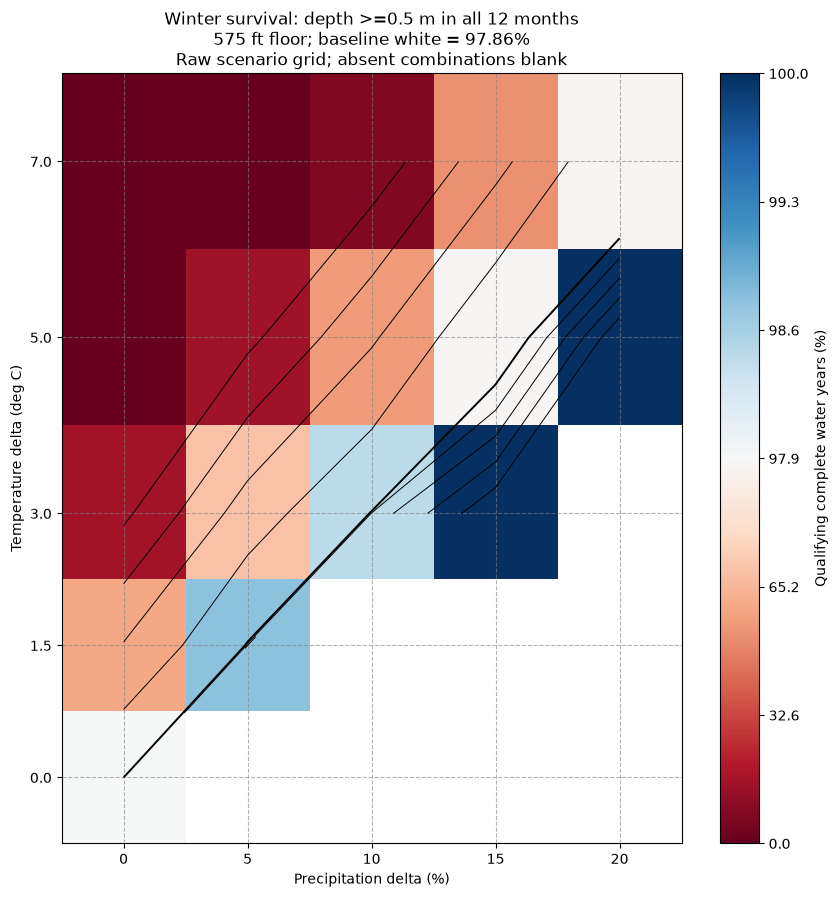

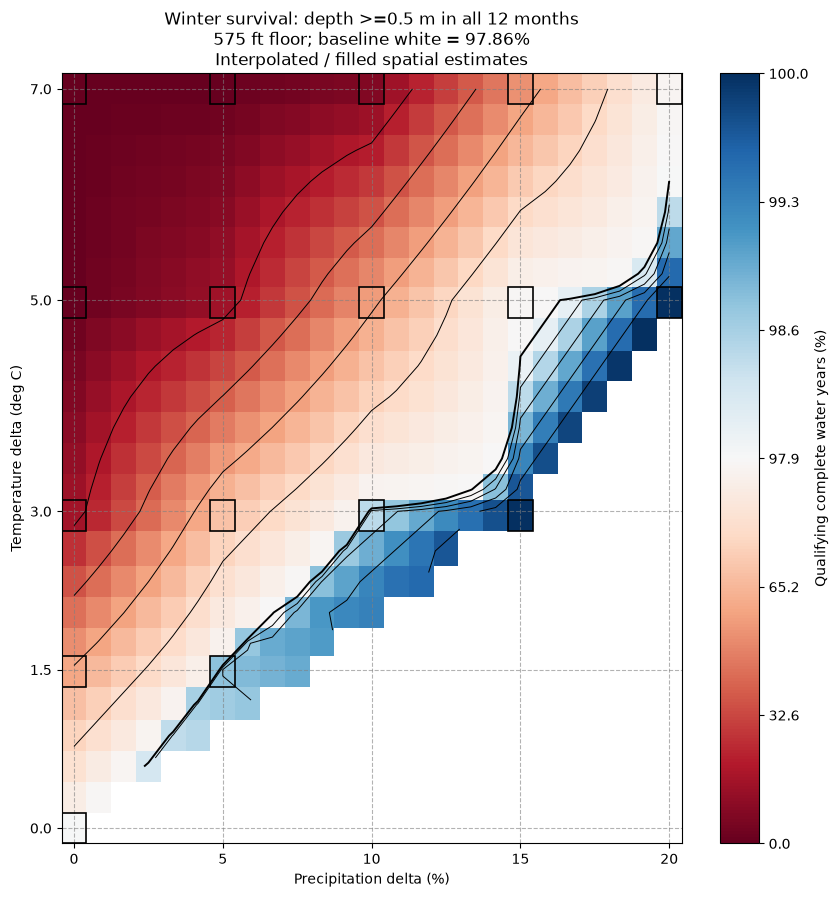

### Growing season: depth 1-3 m in all May-Aug months; rise <=0.15 m/month

Precipitation delta (%),0.0,5.0,10.0,15.0,20.0
Temperature delta (deg C),,,,,
0.0,79.029,NaN,NaN,NaN,NaN
1.5,29.709,83.107,NaN,NaN,NaN
3.0,2.718,38.155,83.301,98.350,NaN
5.0,0.000,2.718,30.097,82.427,97.961
7.0,0.000,0.000,1.553,29.417,84.078


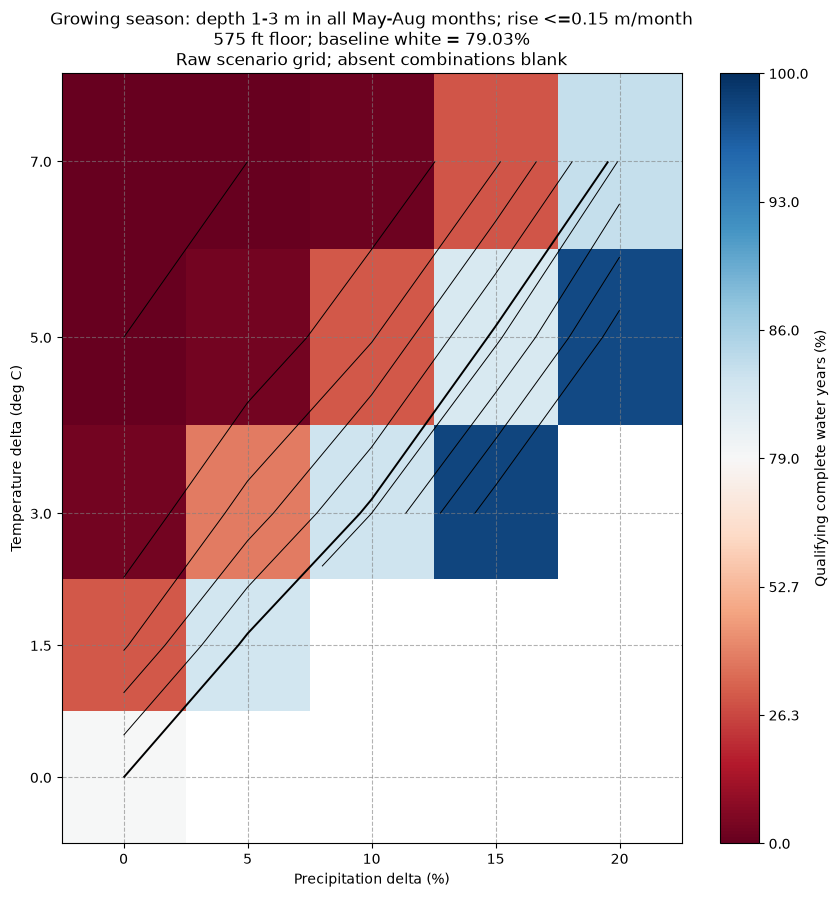

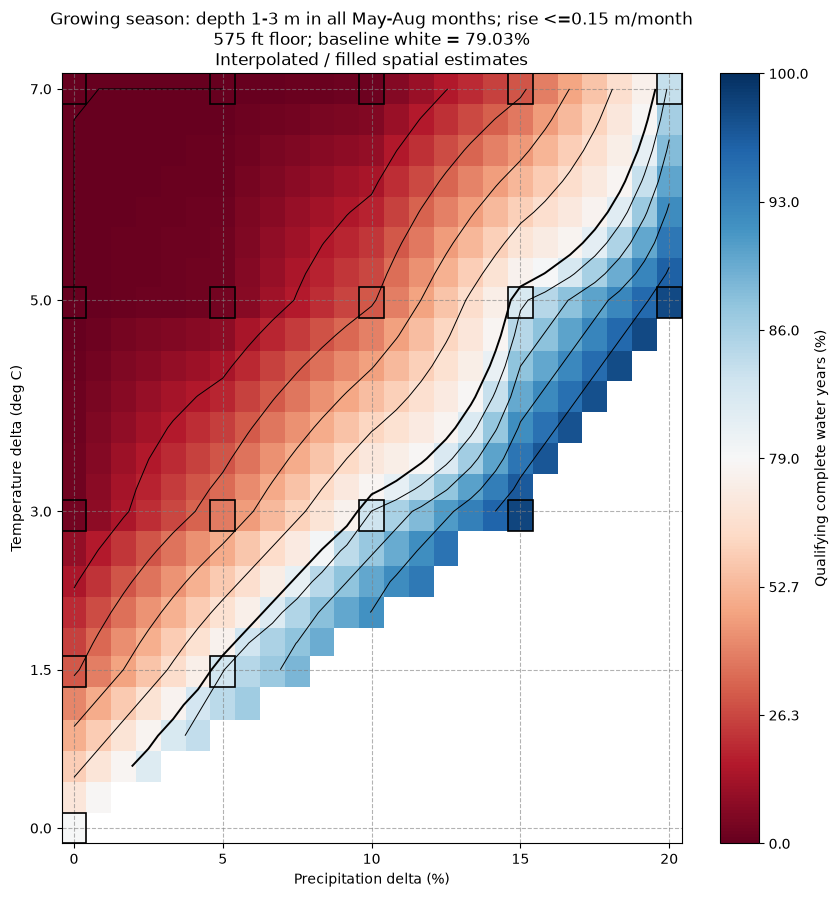

In [7]:
surface_titles = {
    winter.name: 'Winter survival: depth >=0.5 m in all 12 months',
    growing.name: 'Growing season: depth 1-3 m in all May-Aug months; rise <=0.15 m/month',
}
surface_grids = {}
for component in (winter, growing):
    component_summary = summary.loc[component.name]
    baseline_percentage = float(component_summary.loc['_0_0', 'Percentage'])
    if not np.isfinite(baseline_percentage) or not 0 <= baseline_percentage <= 100:
        raise ValueError('A known baseline percentage in [0, 100] is required.')
    if 0 < baseline_percentage < 100:
        surface_norm = TwoSlopeNorm(vmin=0, vcenter=baseline_percentage, vmax=100)
    else:
        surface_norm = Normalize(vmin=baseline_percentage - 100,
                                 vmax=baseline_percentage + 100)
    contour_levels = tuple(surface_norm.inverse(np.linspace(0, 1, 11)))
    color_ticks = surface_norm.inverse(np.linspace(0, 1, 7)).tolist()
    assert np.isclose(surface_norm(baseline_percentage), 0.5)
    assert np.isclose(color_ticks[3], baseline_percentage)
    values = component_summary['Percentage'].to_dict()
    precipitation, temperature, grid = build_grid(scenario_names, values)
    surface_grids[component.name] = (precipitation, temperature, grid)
    display(Markdown(f'### {surface_titles[component.name]}'))
    display(pd.DataFrame(grid, index=pd.Index(temperature, name='Temperature delta (deg C)'),
                         columns=pd.Index(precipitation, name='Precipitation delta (%)')).round(3))
    for interpolate, fillin, subtitle in [
        (False, False, 'Raw scenario grid; absent combinations blank'),
        (True, True, 'Interpolated / filled spatial estimates'),
    ]:
        if fillin and component_summary['Unknown years'].gt(0).any():
            print('Filled surface withheld: resolve unknown annual outcomes first.')
            continue
        plot_response_surface(
            precipitation, temperature, grid.copy(), interpolate=interpolate, fillin=fillin,
            labels=('Precipitation delta (%)', 'Temperature delta (deg C)',
                    'Qualifying complete water years (%)'),
            title=(f'{surface_titles[component.name]}\n'
                   f'{BOTTOM_FT:.0f} ft floor; baseline white = {baseline_percentage:.2f}%\n'
                   f'{subtitle}'), threshold=baseline_percentage,
            norm=surface_norm, levels=contour_levels,
            widths=tuple(1.4 if i == 5 else 0.7 for i in range(len(contour_levels))),
            color_map_ticks=color_ticks, show=True,
        )
        plt.close('all')


In [8]:
interpretation = ['## Computed interpretation', '']
for component in (winter, growing):
    rows = summary.loc[component.name]
    baseline_row = rows.loc['_0_0']
    interpretation.append(
        f"- **{component.name.replace('_', ' ').capitalize()}**: baseline qualifies in "
        f"{int(baseline_row['Qualifying years']):,}/{int(baseline_row['Complete years']):,} "
        f"complete years (**{baseline_row['Percentage']:.2f}%**). "
        f"Across evaluated scenarios, percentages range from {rows['Percentage'].min():.2f}% "
        f"to {rows['Percentage'].max():.2f}%.")
depth_failures = int(diagnostics.loc['All May-Aug months: depth 1-3 m', 'Failed years'])
rise_failures = int(diagnostics.loc['All May-Aug months: rise <=0.15 m (May passes)', 'Failed years'])
interpretation.extend([
    '',
    f'Baseline growing-season depth conditions fail in **{depth_failures:,} years**, '
    f'and the rise condition fails in **{rise_failures:,} years**. These counts may overlap.',
    '',
    'Warmer/drier scenarios can lower levels enough to violate minimum depth, while '
    'higher levels can improve winter submergence yet violate the growing-season upper '
    'depth limit. The bounded growing condition therefore need not respond monotonically '
    'to lake level. Read those mechanisms alongside the computed scenario values, not as '
    'an assumed climate trend.',
    '',
    'The percentages describe this supplied record, not independent annual probabilities '
    'or observed pondweed survival rates. Serial dependence and model/scenario uncertainty '
    f'are not quantified. The {BOTTOM_FT:.0f} ft floor is held fixed: no subsidence, erosion, or datum '
    'offset is modeled.',
])
display(Markdown('\n'.join(interpretation)))


## Computed interpretation

- **Winter survival**: baseline qualifies in 1,008/1,030 complete years (**97.86%**). Across evaluated scenarios, percentages range from 0.00% to 100.00%.
- **Growing season habitat**: baseline qualifies in 814/1,030 complete years (**79.03%**). Across evaluated scenarios, percentages range from 0.00% to 98.35%.

Baseline growing-season depth conditions fail in **203 years**, and the rise condition fails in **15 years**. These counts may overlap.

Warmer/drier scenarios can lower levels enough to violate minimum depth, while higher levels can improve winter submergence yet violate the growing-season upper depth limit. The bounded growing condition therefore need not respond monotonically to lake level. Read those mechanisms alongside the computed scenario values, not as an assumed climate trend.

The percentages describe this supplied record, not independent annual probabilities or observed pondweed survival rates. Serial dependence and model/scenario uncertainty are not quantified. The 575 ft floor is held fixed: no subsidence, erosion, or datum offset is modeled.